# Frequency, severity and pure premium models

This notebook builds the M3 models on `mart_person_year` and explains each step for a reviewer. Several
candidate model structures predict the same quantity, the expected annual PMI-scope cost of a person-year at
2023 prices. They are compared on one yardstick before one is chosen. The notebook uses aggregated tables
only and shows no person-level rows.

**Source.** AHRQ, Medical Expenditure Panel Survey (MEPS), Household Component, full-year consolidated files
HC-243 (2022) and HC-251 (2023), with the inpatient, outpatient and office-based event files.

## Data and metrics

**Which rows.** Models are fitted on the 2022 `train` rows, and scored on the 2022 `test` rows. The test rows
are a household-grouped sample of 2022, so no household is on both sides. The 2023 rows are held back for
the out-of-time test in M5 and are not loaded here.

**What is predicted.** One row is one person-year. A prediction is the expected annual cost of that
person-year, with its exposure included, so a part-year person has a smaller expected cost. Costs are at 2023
prices. Models are fitted unweighted, because an insurer would fit on its own book.

**Factors.** The 18 rating factor candidates are typed as categories. The reference level of each is the level
with the most train exposure, and it can never be `not_applicable` or `unknown`. Age is shown in single years
here. Banding comes in the level grouping task.

**Metrics.** Every candidate is scored by the same package code.

- **Tweedie deviance** on annual cost, with power 1.5. The ranking is re-checked at 1.3 and 1.7.
- **Gini**, weighted by exposure, for how well the predictions rank the person-years.
- **Lift and double-lift** tables, which compare actual with expected cost by group.
- **A/E** (actual divided by expected) overall, by factor level and by predicted-cost decile. A decile is a
  tenth of the exposure, ordered by predicted cost per exposure year, so a part-year person is placed by their
  annual rate.

In [1]:
import pandas as pd

from health_pricing.models import frame, metrics

pd.options.display.float_format = "{:,.3f}".format
frames = frame.load_frames()
frame.frame_summary(frames)

,split,person_years,exposure,claimants,claimant_rate,zero_cost_claimants,claims,cost,mean_cost_per_claimant
0,train,17596,"17,440.750",7229,0.411,34,53322,"38,080,040.270","5,267.677"
1,test,4151,"4,100.333",1731,0.417,6,12463,"9,748,983.247","5,631.995"


About 41 to 42 percent of person-years have at least one PMI-scope claim in both splits. Mean cost per claimant is
higher in test than in train, which is the first sign of how much a skewed cost varies between samples.
A few claimants have a claim of zero cost, counted in the `zero_cost_claimants` column. They count as claimants, and the severity
models will need to treat them explicitly.

### Reference levels

Age has the most exposure at 85 only because single years are not yet banded, so its reference level is
temporary. The reference levels of the other factors are the largest groups, as intended.

In [2]:
frame.reference_table(frames)

,factor,reference_level,exposure_share
0,age,85,0.022
1,region,3,0.384
2,inscov,1,0.592
3,rthlth,2,0.325
4,mnhlth,2,0.311
5,OFTSMK53,3,0.702
6,PHYEXE53,1,0.400
7,HIBPDX,0,0.500
8,CHDDX,0,0.756
9,ANGIDX,0,0.787


### Baseline

The baseline predicts the same cost per exposure year for everyone, the train mean. Every candidate has to beat
it. Its Gini is 0 by construction, because it does not rank anyone, and its A/E on train is 1.

In [3]:
metrics.baseline_scores(frames.train, frames.test)

,split,tweedie_deviance,mean_tweedie_deviance,gini,a_e
0,train,"3,694,004.075",209.934,0.000,1.000
1,test,"928,363.961",223.648,0.000,1.089


In [4]:
baseline = metrics.baseline_predictions(frames.train, frames.test)
pd.DataFrame(metrics.deviance_by_power(frames.test["cost"], baseline), index=["Test deviance"])

,1.300,1.500,1.700
Test deviance,"4,118,785.057","928,363.961","252,758.818"


The baseline's test A/E is above 1, so test cost per exposure year is higher than train. Part of this is
sampling variation in a skewed cost. Every candidate's test A/E should be read against this starting gap.
Deviances at different powers are on different scales, so they are only compared between candidates at the
same power. The power check asks whether the ranking of candidates changes.

## Benefit types

The stacked candidate (c) models the two benefit types separately. `mart_person_year_benefit` has two rows for
every person-year, with zeros where there is nothing to count. Event counts and costs add up to the claim
columns of the main modelling table.

- **Inpatient and day-case.** Every in-scope inpatient stay, and every in-scope outpatient or office-based visit
  where a surgical procedure was performed on the visit (`SURGPROC` = 1).
- **Outpatient.** All other in-scope visits. Visits where the procedure flag is inapplicable, refused or
  unknown are counted here.

The tables use 2023 prices and cover the modelling population.

In [5]:
from health_pricing import eda
from health_pricing.models import benefit

con = eda.connect()
benefit.benefit_summary(con)

,year,benefit_type,person_years,claimants,events,cost_2023_prices,events_share,cost_2023_prices_share
0,2022,inpatient_daycase,21747,"2,464.000","4,863.000","22,715,964.261",0.074,0.475
1,2022,outpatient,21747,"8,468.000","60,922.000","25,113,059.256",0.926,0.525
2,2023,inpatient_daycase,18463,"2,228.000","4,548.000","25,137,095.400",0.074,0.538
3,2023,outpatient,18463,"7,381.000","56,633.000","21,567,598.100",0.926,0.462


### What the procedure flag moves

This table covers every in-scope event in the event files, including people outside the modelling population,
at the prices of each survey year. The `all in-scope events` rows include the inpatient stays, which are never
moved. The flag moves a small share of events but a large share of cost, mainly in hospital outpatient visits.
The flag is a yes or no for the whole visit, so a minor procedure in a doctor's office counts as day-case.

In [6]:
shift = benefit.surgproc_shift(con)
con.close()
shift

,year,event_type,events,moved_events,cost,moved_cost,moved_events_share,moved_cost_share
0,2022,office_based,52602,2692,"19,541,406.280","2,808,890.470",0.051,0.144
1,2022,outpatient,13084,1506,"14,573,992.140","6,525,104.460",0.115,0.448
2,2022,all in-scope events,66406,4198,"47,120,394.730","9,333,994.930",0.063,0.198
3,2023,office_based,49654,2388,"17,166,857.780","2,122,309.290",0.048,0.124
4,2023,outpatient,11378,1459,"13,087,546.120","6,369,904.530",0.128,0.487
5,2023,all in-scope events,61792,3847,"47,159,982.900","8,492,213.820",0.062,0.180


## Leakage check on the unknown level

Adults who were never asked a question have the level `unknown`. For example, people who left the survey before
round 5/3, or who died before the priority-conditions section, are not asked the smoking, exercise or condition
questions. If `unknown` is really a marker for leaving or dying, it would predict cost for the wrong reason and
could not be used when pricing a policy. This section tests that on the 13 candidate factors that have an
`unknown` level. It uses adults in the 2022 train split only.

For each variable, adults at `unknown` are compared with adults who gave an answer. People who refused or did not
know are in neither group.

In [7]:
import matplotlib.pyplot as plt

from health_pricing.models import leakage

adults = leakage.load_leakage_frame()
comparison = leakage.unknown_level_table(adults)
comparison

,variable,group,person_years,mean_age,share_under_25,share_left_survey_early,share_exposure_under_1,mean_exposure,claimant_rate,mean_cost_per_claimant,cost_per_exposure_year
0,OFTSMK53,unknown,186,71.430,0.027,0.747,0.892,0.509,0.398,"27,712.301","21,643.380"
1,OFTSMK53,answered,13895,51.746,0.082,0.000,0.001,1.000,0.468,"5,293.445","2,476.125"
2,PHYEXE53,unknown,186,71.430,0.027,0.747,0.892,0.509,0.398,"27,712.301","21,643.380"
3,PHYEXE53,answered,13859,51.753,0.082,0.000,0.001,1.000,0.469,"5,290.742","2,479.764"
4,HIBPDX,unknown,113,29.062,0.805,0.177,0.212,0.829,0.230,"1,730.804",480.437
5,HIBPDX,answered,14080,52.146,0.077,0.008,0.011,0.994,0.467,"5,556.539","2,608.726"
6,CHDDX,unknown,113,29.062,0.805,0.177,0.212,0.829,0.230,"1,730.804",480.437
7,CHDDX,answered,14083,52.145,0.077,0.008,0.011,0.994,0.467,"5,550.613","2,604.990"
8,ANGIDX,unknown,113,29.062,0.805,0.177,0.212,0.829,0.230,"1,730.804",480.437
9,ANGIDX,answered,14084,52.143,0.077,0.008,0.011,0.994,0.467,"5,551.442","2,604.796"


The smoking and exercise questions have the same 186 adults at `unknown`. The nine adult-only condition flags have the
same 113, and the two flags asked at any age have the same 24. So the 13 rows above are only three different
groups of people.

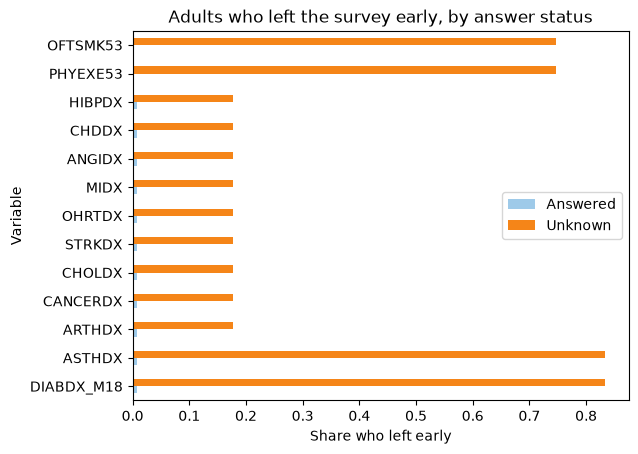

In [8]:
wide = comparison.pivot(index="variable", columns="group", values="share_left_survey_early")
ax = wide.loc[leakage.UNKNOWN_VARIABLES[::-1]].plot.barh(
    color={"answered": "#9ecae9", "unknown": "#f58518"}
)
ax.set_title("Adults who left the survey early, by answer status")
ax.set_xlabel("Share who left early")
ax.set_ylabel("Variable")
ax.legend(["Answered", "Unknown"], title=None)
plt.show()

### The other direction

Of the adults who left the survey early, what share are `unknown`? If it is close to all of them, `unknown` is a
leaver marker.

In [9]:
leavers = leakage.unknown_by_leaver_table(adults)
leavers

,variable,leavers,leavers_unknown_share,stayers_unknown_share
0,OFTSMK53,139,1.000,0.003
1,PHYEXE53,139,1.000,0.003
2,HIBPDX,137,0.146,0.007
3,CHDDX,137,0.146,0.007
4,ANGIDX,137,0.146,0.007
5,MIDX,137,0.146,0.007
6,OHRTDX,137,0.146,0.007
7,STRKDX,137,0.146,0.007
8,CHOLDX,137,0.146,0.007
9,CANCERDX,137,0.146,0.007


### What merging unknown into the reference level would do

The reference level is the answered level with the most exposure. If `unknown` were merged into it, the reference
cost per exposure year would move as shown. A large move means the `unknown` person-years would distort the
reference and so every relativity of that factor.

In [10]:
leakage.merge_effect_table(adults)

,variable,reference_level,unknown_share_of_reference_exposure,reference_cost_per_exposure_year,cost_after_merge,change_after_merge
0,OFTSMK53,3,0.008,"2,537.876","2,684.859",0.058
1,PHYEXE53,1,0.014,"2,152.138","2,414.039",0.122
2,HIBPDX,0,0.011,"1,700.895","1,687.882",-0.008
3,CHDDX,0,0.007,"2,294.469","2,281.653",-0.006
4,ANGIDX,0,0.007,"2,561.540","2,547.415",-0.006
5,MIDX,0,0.007,"2,454.519","2,440.842",-0.006
6,OHRTDX,0,0.008,"2,244.590","2,231.249",-0.006
7,STRKDX,0,0.007,"2,464.154","2,450.315",-0.006
8,CHOLDX,0,0.010,"1,828.378","1,814.463",-0.008
9,CANCERDX,0,0.008,"2,019.838","2,008.057",-0.006


### Recommendation for each variable

The decision is taken in the level grouping task. This is the evidence-based recommendation to it. No variable
should be dropped.

| Variables | What the evidence shows | Recommendation |
|---|---|---|
| `OFTSMK53`, `PHYEXE53` | 186 adult person-years. 75 percent left the survey early, 89 percent are part-year, the mean age is 71, and the cost per exposure year is about 21,600 dollars against about 2,500 for adults who answered. Every adult who left early is `unknown`. | **Keep the level in the fit only**, as a control that absorbs the leaver effect. Merging it would raise the reference cost by 5.8 percent for smoking and 12.2 percent for exercise. At rating, treat everyone as the reference level, and never offer `unknown` as a rating level. |
| The nine adult-only condition flags | 113 adult person-years, about 79 percent aged exactly 18, with a low cost per exposure year of about 480 dollars. Most are people who turned 18 during the year. A minority (18 percent) left early, and only 15 percent of leavers are `unknown`. | **Merge into the reference level** (`0`). The reference cost moves by less than 1 percent. |
| `ASTHDX`, `DIABDX_M18` | 24 adult person-years with about 5 years of exposure between them. Most (83 percent) left early. | **Merge into the reference level** (`0`). The reference cost moves by less than 0.1 percent. |

## Rating-factor levels (decision gate 6)

Before any model is fitted, the levels of each rating factor candidate have to be agreed. Levels with few claimants
give unstable relativities, so they are merged. This section shows the evidence and the grouping. The user
approved it at decision gate 6 on 2 November 2026, with the two changes noted below.

All counts are for the 2022 train split. A **claimant** is a person-year with at least one claim. A level is
**thin** if it has fewer than 30 claimants. The `unknown` level is explained in the leakage check above, and
`not_applicable` is a child on an adult-only question.

In [11]:
from health_pricing.models import frame, levels

frames = frame.load_frames()
evidence = levels.level_evidence(frames.train)
evidence[evidence["factor"] != "age"]

,factor,level,person_years,exposure,claimants,claims,claimant_rate,cost_per_exposure_year,thin
86,region,1,2795,"2,771.250",1319,11562,0.472,"2,636.650",False
87,region,2,3535,"3,504.917",1530,10605,0.433,"2,294.140",False
88,region,3,6764,"6,704.333",2507,17826,0.371,"2,015.656",False
89,region,4,4502,"4,460.250",1873,13329,0.416,"2,066.885",False
90,inscov,1,10382,"10,321.333",4504,32037,0.434,"2,242.807",False
...,...,...,...,...,...,...,...,...,...
164,ASTHDX,unknown,43,8.167,5,7,0.116,"11,458.065",True
165,DIABDX_M18,0,15520,"15,423.500",5966,42762,0.384,"1,902.738",False
166,DIABDX_M18,1,2024,"2,002.167",1257,10548,0.621,"4,314.496",False
167,DIABDX_M18,missing,9,6.917,1,5,0.111,180.120,True


### Thin levels

Every thin level below is a placeholder (`missing` or `unknown`) and not a real answer. No real answer level of any
factor is thin. Single years of age are left out here. Some are thin, and they are banded in the next section.

In [12]:
thin = evidence[evidence["thin"] & (evidence["factor"] != "age")]
thin

,factor,level,person_years,exposure,claimants,claims,claimant_rate,cost_per_exposure_year,thin
98,rthlth,missing,49,7.833,7,10,0.143,"6,740.051",True
104,mnhlth,missing,50,8.417,7,10,0.140,"6,272.918",True
118,HIBPDX,missing,17,15.917,0,0,0.000,0.000,True
120,HIBPDX,unknown,113,93.667,26,160,0.230,480.437,True
123,CHDDX,missing,14,12.917,1,5,0.071,"3,445.576",True
125,CHDDX,unknown,113,93.667,26,160,0.230,480.437,True
128,ANGIDX,missing,13,11.917,2,7,0.154,"3,743.665",True
130,ANGIDX,unknown,113,93.667,26,160,0.230,480.437,True
133,MIDX,missing,8,6.917,0,0,0.000,0.000,True
135,MIDX,unknown,113,93.667,26,160,0.230,480.437,True


### Age bands

Claimant rate rises steadily from the late twenties to the late seventies. It dips after 80, where age is capped at
85 and the top group mixes everyone aged 80 and over. Two proposals are compared. **Five-year bands** have 16 bands
and the fewest claimants in any band is 108. **Ten-year bands** have 10 bands and the fewest is also 108. The ten-year
bands hide some of the slope inside a band, for example the claimant rate rises from 49 to 56 percent within the
ages 55 to 64.

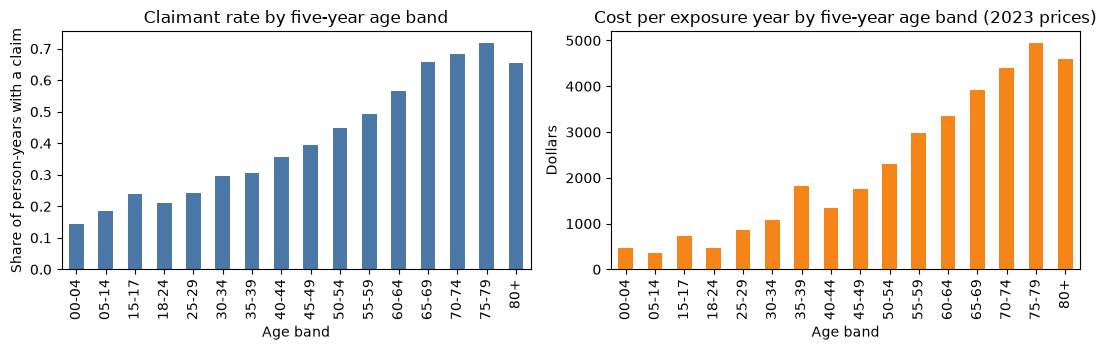

,band,person_years,exposure,claimants,claimant_rate,cost_per_exposure_year,thin
0,00-04,749,693.250,108,0.144,463.111,False
1,05-14,2004,"2,002.417",369,0.184,362.918,False
2,15-17,634,634.000,152,0.240,723.324,False
3,18-24,1173,"1,168.917",247,0.211,466.591,False
4,25-29,947,944.667,229,0.242,868.374,False
5,30-34,1021,"1,019.583",303,0.297,"1,075.215",False
6,35-39,1119,"1,115.500",341,0.305,"1,813.724",False
7,40-44,1048,"1,046.167",372,0.355,"1,346.983",False
8,45-49,996,994.333,392,0.394,"1,753.727",False
9,50-54,1128,"1,126.833",505,0.448,"2,297.019",False


In [13]:
import matplotlib.pyplot as plt

five = levels.age_band_table(frames.train, levels.AGE_BANDS["five_year"])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
five.plot.bar(x="band", y="claimant_rate", ax=axes[0], legend=False, color="#4c78a8")
axes[0].set_title("Claimant rate by five-year age band")
axes[0].set_xlabel("Age band")
axes[0].set_ylabel("Share of person-years with a claim")
five.plot.bar(x="band", y="cost_per_exposure_year", ax=axes[1], legend=False, color="#f58518")
axes[1].set_title("Cost per exposure year by five-year age band (2023 prices)")
axes[1].set_xlabel("Age band")
axes[1].set_ylabel("Dollars")
plt.tight_layout()
plt.show()
five

In [14]:
levels.age_band_table(frames.train, levels.AGE_BANDS["ten_year"])

,band,person_years,exposure,claimants,claimant_rate,cost_per_exposure_year,thin
0,00-04,749,693.250,108,0.144,463.111,False
1,05-14,2004,"2,002.417",369,0.184,362.918,False
2,15-17,634,634.000,152,0.240,723.324,False
3,18-24,1173,"1,168.917",247,0.211,466.591,False
4,25-34,1968,"1,964.250",532,0.270,975.739,False
5,35-44,2167,"2,161.667",713,0.329,"1,587.839",False
6,45-54,2124,"2,121.167",897,0.422,"2,042.342",False
7,55-64,2512,"2,503.583",1332,0.530,"3,163.104",False
8,65-74,2486,"2,468.250",1663,0.669,"4,141.346",False
9,75+,1779,"1,723.250",1216,0.684,"4,762.043",False


### Rules (approved at gate 6)

| Case | Rule | Why |
|---|---|---|
| Age | Five-year bands as above, with 0 to 4, 5 to 14, 15 to 17 and 18 to 24 for the young and 80 and over as the top band | The claimant rate keeps rising from age 25 to 79, by up to 9 points per five years. Each band has at least 100 claimants |
| `not_applicable` (a child on an adult-only question) | Merge into the reference level | A child cannot be a smoker or have an adult condition flag. The age bands carry the effect of being a child. A separate level would only repeat the child age bands |
| `unknown` on `OFTSMK53` and `PHYEXE53` | Keep as a level in the fit only, and price it at the reference | The leakage check shows it marks adults who left the survey early. Merging it would distort the reference cost by 6 and 12 percent |
| `unknown` on the 11 condition flags | Merge into the reference level | The leakage check shows a small, mostly young group with low cost. Merging moves the reference cost by under 1 percent. The test applied at the gate is that `unknown` is kept as a control wherever merging would move the reference cost by more than 2 percent, and the table below shows it is met by `OFTSMK53` and `PHYEXE53` only |
| Null (refused, don't know, cannot be computed, or no valid round for health status) | Merge into the reference level | At most 165 person-years for any factor, so the effect on the reference level is small |
| Any other level with fewer than 30 claimants | Merge into the reference level | No real answer level is thin today, so this rule changes nothing now. It is a safeguard for later refits |
| Reference level | The real answer with the most exposure, never a placeholder | The usual convention. It can be rebased to another level when relativities are presented, without changing the model. For age, relativities are presented against the adult band with the most exposure, and the technical reference stays 5 to 14 |

The next table shows the gate 6 test for each variable with an `unknown` level. It is the change in the reference
cost per exposure year if `unknown` were merged into the reference level, using adults in the train split. Only the
smoking and exercise questions are above 2 percent, so only they keep `unknown` as a control.

In [15]:
rule = levels.unknown_rule_table()
rule[
    [
        "variable",
        "reference_level",
        "unknown_share_of_reference_exposure",
        "change_after_merge",
        "exceeds_limit",
        "kept_as_control",
    ]
]

,variable,reference_level,unknown_share_of_reference_exposure,change_after_merge,exceeds_limit,kept_as_control
0,OFTSMK53,3,0.008,0.058,True,True
1,PHYEXE53,1,0.014,0.122,True,True
2,HIBPDX,0,0.011,-0.008,False,False
3,CHDDX,0,0.007,-0.006,False,False
4,ANGIDX,0,0.007,-0.006,False,False
5,MIDX,0,0.007,-0.006,False,False
6,OHRTDX,0,0.008,-0.006,False,False
7,STRKDX,0,0.007,-0.006,False,False
8,CHOLDX,0,0.010,-0.008,False,False
9,CANCERDX,0,0.008,-0.006,False,False


In [16]:
grouping = levels.decided_grouping(frames)
summary = levels.grouping_summary(frames, grouping)
summary[summary["factor"] != "age"]

,factor,group,reference,levels_merged,person_years,exposure,claimants
16,region,1,False,1,2795,"2,771.250",1319
17,region,2,False,2,3535,"3,504.917",1530
18,region,3,True,3,6764,"6,704.333",2507
19,region,4,False,4,4502,"4,460.250",1873
20,inscov,1,True,1,10382,"10,321.333",4504
21,inscov,2,False,2,6040,"5,962.833",2630
22,inscov,3,False,3,1174,"1,156.583",95
23,rthlth,1,False,1,4459,"4,413.667",1115
24,rthlth,2,True,"2, missing",5745,"5,680.750",2414
25,rthlth,3,False,3,5167,"5,146.250",2301


In [17]:
technical = grouping.reference["age"]
presentation = levels.presentation_age_reference(frames, grouping)
print(
    f"Technical age reference: {technical}. Age relativities are presented against: {presentation}."
)
saved = levels.save_grouping(grouping)
print(f"Saved the level map ({len(grouping.table())} rows) to outputs/m3_draft/{saved.name}")

Technical age reference: 05-14. Age relativities are presented against: 65-69.
Saved the level map (169 rows) to outputs/m3_draft/level_grouping.csv


### Insurance coverage: two options for gate 7

`inscov` is any private (1), public only (2) or uninsured (3). The uninsured claimant rate reflects access to care in
the US and not risk. Gate 7 decides whether `inscov` is a permitted rating factor and how to treat it. Two options are
compared on the figures below. **(a)** restricts the modelling population to privately insured persons. **(b)**
keeps everyone, and fits `inscov` as a control that is priced at the private level.

In [18]:
levels.inscov_table(frames.train)

,level,person_years,exposure,claimants,mean_age,share_over_65,share_under_18,claimant_rate,cost_per_exposure_year,person_years_share,exposure_share,claimants_share,cost_share
0,1,10382,"10,321.333",4504,42.220,0.176,0.176,0.434,"2,242.807",0.590,0.592,0.623,0.608
1,2,6040,"5,962.833",2630,47.144,0.400,0.245,0.435,"2,454.049",0.343,0.342,0.364,0.384
2,3,1174,"1,156.583",95,39.386,0.019,0.063,0.081,257.824,0.067,0.066,0.013,0.008


In [19]:
levels.inscov_table(frames.test)

,level,person_years,exposure,claimants,mean_age,share_over_65,share_under_18,claimant_rate,cost_per_exposure_year,person_years_share,exposure_share,claimants_share,cost_share
0,1,2341,"2,322.583",1065,42.983,0.180,0.164,0.455,"2,579.539",0.564,0.566,0.615,0.615
1,2,1514,"1,486.667",643,47.721,0.416,0.246,0.425,"2,464.284",0.365,0.363,0.371,0.376
2,3,296,291.083,23,38.078,0.020,0.105,0.078,323.686,0.071,0.071,0.013,0.010
